In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from fit_file import X_sq
from fit_classes import Data
import scipy.optimize as opt
import scipy.odr as odr
from scipy.stats import chi2

In [2]:
#lijst met alle getallen voor makkelijke data-inlading
getallen = np.arange(1, 213)
data_getallen = np.char.zfill(getallen.astype(str), 3)

In [3]:
#proef 1 - fit voor frequentie
#er wordt uitgegaan van 1 micros per tijdsinterval (pls god)

aan_box_matrix = np.loadtxt('data_107_212/data_107_000.txt', skiprows = 9).T
t = 1e-6 * (aan_box_matrix[0] - 1)
dt = np.full(len(t), 1e-6, float)
V1 = aan_box_matrix[1] #mV → fout is ook in mV

#fitten
def model_sinus(params, t):
    A, f, phi, C = params
    return A * np.sin(2 * np.pi * f * t + phi) + C

param_names = ['A', 'f', r'$\varphi$', 'C']


dV = np.full(len(V1), 1.953125, float)

X_sq(data = ((t, dt), (V1, dV)), param_names = param_names, initial_guess = (np.max(V1), 1013, 1, 1), model = model_sinus, PLOT = False)
#plt.scatter(t[:100], V1[:100]) #hieruit wordt fout gebaseerd (1.953125 mV)
print(np.abs(1031.14673413 - 1031.11576431))


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at      52.49082972     ;     68% CI = [     52.43055155,      52.55110791]
For parameter f        :     Minimum at    1031.14673413     ;     68% CI = [   1031.11576431,    1031.17770427]
For parameter $\varphi$ :     Minimum at      -1.06393150     ;     68% CI = [     -1.06506380,      -1.06279918]
For parameter C        :     Minimum at       0.76240415     ;     68% CI = [      0.72008205,       0.80472628]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        2880.12564276
Reduced χ² value       :     χ²_red           0.28812782
P-value                :     p-value          1.00000000
----------END---------------------------------------------------------------------------------------------------

0.03096981999988202


[9.8679823161846, 5.838534432838292, 6.455943566758797, 7.369998635326627, 7.803895333470731, 7.502576157291459, 7.348862534199917, 6.905778345671301, 5.928820088067023, 7.314633353072771, 5.565977745484121, 4.054642489765588, 3.2063816291806244, 2.1247887865967297, 1.334391430355464, 0.5996219139133294, 0.5130461620876684, 1.2079013458697707, 0.18875120510579757, 0.13035639347202374, 0.13640039080606606, 0.08020579939862342, 0.21597275474297697, 0.12151826357188299, 0.18121374145108013, 0.4705755878783112, 0.8070739523294176, 1.3453571887574443, 2.155439429730145, 3.2169856642515193, 3.6340099611820853, 5.093375643803504, 6.102416671414348, 7.066838613240573]
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 3.635434751327181e-102, 1.0, 1.0, 1.4225160133354616e-43, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 3.228276916714993e-108, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


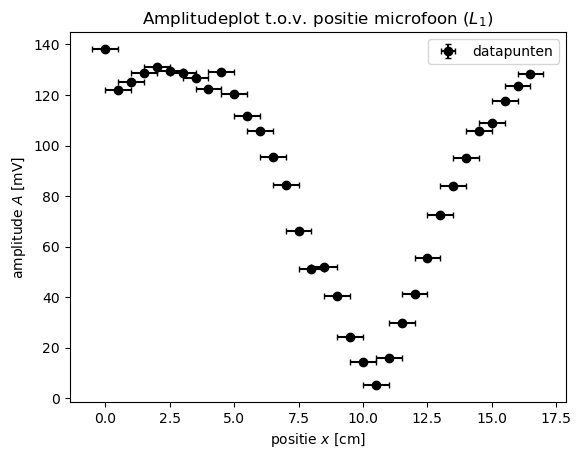

In [17]:
#proef 2 - im kym (008 - 042)
alle_data_matrix = []
for i in data_getallen[7: 42]:
    if i != '025':
        alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])
    else:
        continue

def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A21 = []
alle_p21 = []
alle_chi21 = []
fout_A21 = []

counter = 7

for i in alle_data_matrix:
    counter += 1
    if counter < 29:
        t = 1e-6 * (aan_box_matrix[0] - 1)
        dt = np.full(len(t), 1e-6, float)
        popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
        alle_A21.append(np.abs(popt[0]))
        res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
        alle_p21.append(res[1])
        alle_chi21.append(res[0])
        fout_A = np.sqrt(np.diag(pcov))[0]
        fout_A21.append(fout_A)
        #print(popt)
        #print(np.sqrt(np.diag(pcov)))
        #fig, ax = plt.subplots()
        #ax.scatter(t, i)
        #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
        continue
    if counter == 29:
        t = 4e-6 * (aan_box_matrix[0] - 1)
        dt = np.full(len(t), 4e-6, float)
        popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
        alle_A21.append(np.abs(popt[0]))
        res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
        alle_p21.append(res[1])
        alle_chi21.append(res[0])
        fout_A = np.sqrt(np.diag(pcov))[0]
        fout_A21.append(fout_A)
    else:
        t = 2e-6 * (aan_box_matrix[0] - 1)
        dt = np.full(len(t), 2e-6, float)
        popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
        alle_A21.append(np.abs(popt[0]))
        res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
        alle_p21.append(res[1])
        alle_chi21.append(res[0])
        fout_A = np.sqrt(np.diag(pcov))[0]
        fout_A21.append(fout_A)

x = np.arange(0, 17, 0.5)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A21, fout_A21, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L_1$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi21)
print(alle_p21)

[9.942503492630857, 5.323726015877433, 5.159772914387625, 5.054935544292951, 4.2905518740665505, 2.9502282206250263, 2.0943843210137216, 1.0443100130739447, 0.3390831512177229, 0.16697781727564825, 0.15188156884904488, 0.09367308258698089, 0.18709508334442915, 0.5447446968407095, 1.4943411133810038, 2.8939993593152122, 4.145021648689874, 7.605950601743368, 8.816498857554524, 9.00964402495419, 7.682689011164025, 6.245060245298818, 3.2331560006870506, 1.9768931187530496, 0.6944476642601027, 0.2725781372443029, 0.11935884320296092, 0.11107349470958099, 0.12453977640349631, 0.2789007731101885, 0.695530236452126, 1.6979443582361347, 2.867810102104719, 4.397684949672842]
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.000993547032919476, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 8.670923359808252e-204, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0]


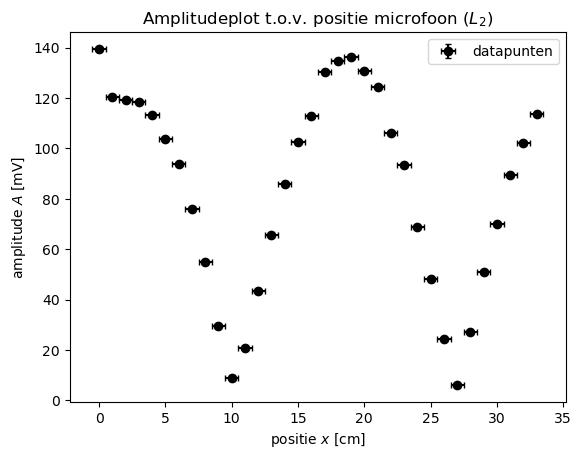

In [20]:
#proef 2 - im kym (043 - 076)
alle_data_matrix = []
for i in data_getallen[42: 76]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A22 = []
alle_p22 = []
alle_chi22 = []
fout_A22 = []

for i in alle_data_matrix:
    t = 2e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
    alle_A22.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p22.append(res[1])
    alle_chi22.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A22.append(fout_A)
    #print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 34, 1)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A22, fout_A22, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L_2$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi22)
print(alle_p22)

[7.631585555043819, 5.3851687073006325, 5.374627923305386, 3.0761125674444294, 1.4692240641522276, 0.3872082640733988, 0.10057570273710426, 0.16220485987106506, 0.23996280386218125, 1.104730430420917, 2.5850319423916486, 4.555183810067007, 5.491780739584883, 5.183649114853262, 3.6251298194292714, 1.5579326591302407, 0.46053566797236717, 0.132459228623182, 0.11241698887743191, 0.26807236637626164, 1.0654975660189991, 2.673054140210157, 4.790040884481478, 5.475361889240959, 5.591074169245768, 3.7390969378768144, 1.7187388756237907, 0.5311704161603791, 0.1544735780562711, 0.1069112823452379, 0.22206059864999428, 0.5547240796141528, 1.5291925831473165, 2.923573656819639]
[0.0, 0.0, 0.0, 0.0, 4.852758150070995e-186, 1.0, 1.0, 1.0, 1.0, 3.8892733010723707e-13, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0513415004779944e-251, 1.0, 1.0, 1.0, 1.0, 2.8429984058862164e-06, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0043112329204147e-229, 0.0]


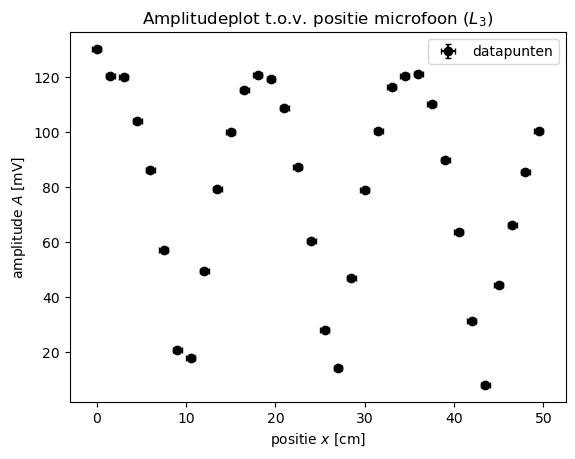

In [19]:
#proef 2 - im kym (077 - 110)
alle_data_matrix = []
for i in data_getallen[76: 110]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A23 = []
alle_p23 = []
alle_chi23 = []
fout_A23 = []

for i in alle_data_matrix:
    t = 2e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
    alle_A23.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p23.append(res[1])
    alle_chi23.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A23.append(fout_A)
    #print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 49.501, 1.5)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A23, fout_A23, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L_3$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi23)
print(alle_p23)

In [7]:
#proef 3 - vernieuwde hoop
data_3 = np.loadtxt('data_107_212/data_107_112.txt', skiprows = 9).T[1]
t = 0.4e-6 * (aan_box_matrix[0] - 1)
dt = np.full(len(t), 0.4e-6, float)
X_sq(data = ((t, dt), (data_3, dV)), param_names = param_names, initial_guess = (np.max(data_3), 2030, 1, 1), model = model_sinus, PLOT = False)
print(np.abs(2029.83419372 -  2029.77754651))


---------START--------------------------------------------------------------------------------------------------
For parameter A        :     Minimum at      72.20974240     ;     68% CI = [     72.14949243,      72.26999235]
For parameter f        :     Minimum at    2029.83419372     ;     68% CI = [   2029.77754651,    2029.89083897]
For parameter $\varphi$ :     Minimum at      -0.46089226     ;     68% CI = [     -0.46171573,      -0.46006878]
For parameter C        :     Minimum at       0.62720649     ;     68% CI = [      0.58488437,       0.66952860]
----------------------------------------------------------------------------------------------------------------
Minimal χ² value       :     χ²_min        7190.94751234
Reduced χ² value       :     χ²_red           0.71938250
P-value                :     p-value          1.00000000
----------END---------------------------------------------------------------------------------------------------

0.05664720999993733


[7.631585555043819, 5.3851687073006325, 5.374627923305386, 3.0761125674444294, 1.4692240641522276, 0.3872082640733988, 0.10057570273710426, 0.16220485987106506, 0.23996280386218125, 1.104730430420917, 2.5850319423916486, 4.555183810067007, 5.491780739584883, 5.183649114853262, 3.6251298194292714, 1.5579326591302407, 0.46053566797236717, 0.132459228623182, 0.11241698887743191, 0.26807236637626164, 1.0654975660189991, 2.673054140210157, 4.790040884481478, 5.475361889240959, 5.591074169245768, 3.7390969378768144, 1.7187388756237907, 0.5311704161603791, 0.1544735780562711, 0.1069112823452379, 0.22206059864999428, 0.5547240796141528, 1.5291925831473165, 2.923573656819639]
[0.0, 0.0, 0.0, 0.0, 4.852758150070995e-186, 1.0, 1.0, 1.0, 1.0, 3.8892733010723707e-13, 0.0, 0.0, 0.0, 0.0, 0.0, 2.0513415004779944e-251, 1.0, 1.0, 1.0, 1.0, 2.8429984058862164e-06, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 2.0043112329204147e-229, 0.0]


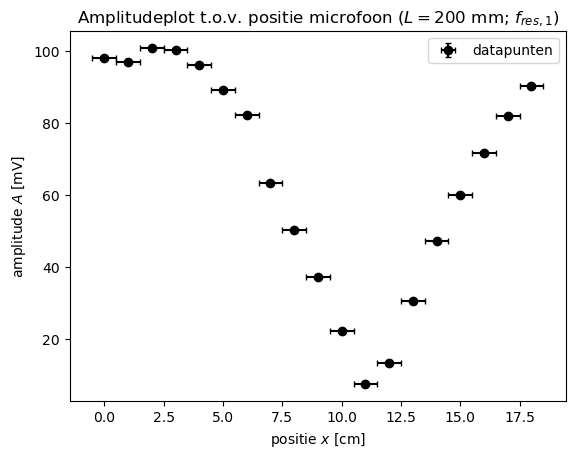

In [ ]:
#proef 4 - we going (118-136)
alle_data_matrix = []
for i in data_getallen[117: 136]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A41 = []
alle_p41 = []
alle_chi41 = []
fout_A41 = []

for i in alle_data_matrix:
    t = 1e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1031.14673413, 1, 1], dV)
    alle_A41.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p41.append(res[1])
    alle_chi41.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A41.append(fout_A)
    #print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 19, 1)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A41, fout_A41, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L = 200 \ \text{mm}$; $f_{res, 1}$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi41)
print(alle_p41)

[9.942503492630857, 5.323726015877433, 5.159772914387625, 5.054935544292951, 4.2905518740665505, 2.9502282206250263, 2.0943843210137216, 1.0443100130739447, 0.3390831512177229, 0.16697781727564825, 0.15188156884904488, 0.09367308258698089, 0.18709508334442915, 0.5447446968407095, 1.4943411133810038, 2.8939993593152122, 4.145021648689874, 7.605950601743368, 8.816498857554524, 9.00964402495419, 7.682689011164025, 6.245060245298818, 3.2331560006870506, 1.9768931187530496, 0.6944476642601027, 0.2725781372443029, 0.11935884320296092, 0.11107349470958099, 0.12453977640349631, 0.2789007731101885, 0.695530236452126, 1.6979443582361347, 2.867810102104719, 4.397684949672842]
[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.000993547032919476, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 8.670923359808252e-204, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.0, 0.0, 0.0]


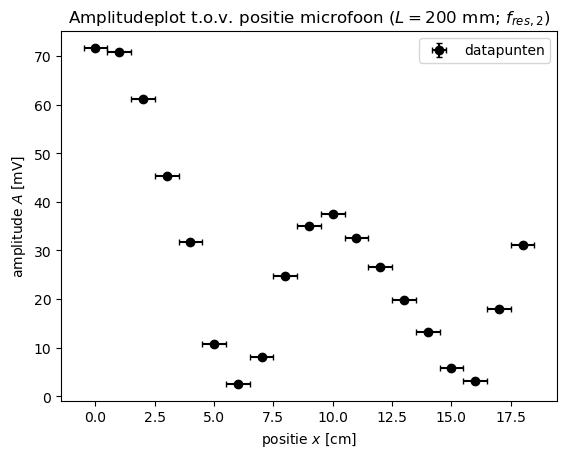

In [ ]:
#proef 4 - we going (137-155)
alle_data_matrix = []
for i in data_getallen[136: 155]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A42 = []
alle_p42 = []
alle_chi42 = []
fout_A42 = []

for i in alle_data_matrix:
    t = 1e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1800, 1, 1], dV)
    alle_A42.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p42.append(res[1])
    alle_chi42.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A42.append(fout_A)
    #print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 19, 1)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A42, fout_A42, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L = 200 \ \text{mm}$; $f_{res, 2}$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi42)
print(alle_p42)


[-57.6592882  666.91819404   0.95775166   1.02342424]
[-48.05317795 670.53870369   0.85060471   0.91474933]
[-49.56332805 670.53785234   0.85468883   0.78007138]
[-47.52491232 670.24995494   0.86025631   0.83073483]
[-44.96642359 669.90943996   0.8738528    0.81529301]
[-40.10021618 669.99993993   0.86525394   0.82862666]
[-35.78660454 669.91893795   0.86488255   0.87025447]
[-28.14737659 669.70422874   0.87963598   0.74011184]
[-22.18469853 669.91968615   0.85530868   0.79089415]
[-15.49840816 669.86790042   0.84287867   0.78649931]
[ -8.57782235 669.80280013   0.72279135   0.85284076]
[-2.55350572e+00  6.69833263e+02  6.55654965e-01  6.99118295e-01]
[ -8.91956196 669.94253222   0.77513415   0.80913065]
[-17.32573514 669.97090453   0.82478499   0.89798084]
[-25.90882525 669.86272191   0.86802779   0.82922489]
[-34.61677836 670.00285855   0.85365024   0.88639609]
[-38.72582819 669.94448226   0.8665716    0.80054224]
[-43.94740984 669.9377433    0.87598399   0.81871068]
[-47.11760869 66

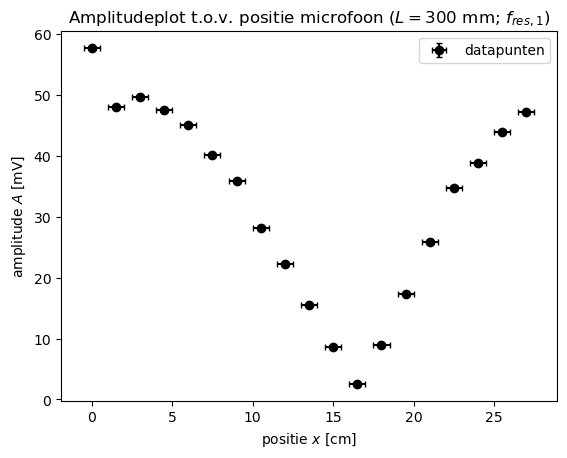

In [10]:
#proef 5 - wanneer stopt het (156 - 174)
alle_data_matrix = []
for i in data_getallen[155: 174]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A51 = []
alle_p51 = []
alle_chi51 = []
fout_A51 = []

for i in alle_data_matrix:
    t = 1e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 670.2, 1, 1], dV)
    alle_A51.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p51.append(res[1])
    alle_chi51.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A51.append(fout_A)
    print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 27.001, 1.5)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A51, fout_A51, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L = 300 \ \text{mm}$; $f_{res, 1}$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi23)

[-1.21576319e+02  1.24349093e+03  1.66981859e+00  7.72471063e-01]
[-1.27907624e+02  1.24370844e+03  1.66016159e+00  6.36142696e-01]
[-1.39167129e+02  1.24452009e+03  1.63547282e+00  5.56815602e-01]
[-1.30480000e+02  1.24406672e+03  1.65272582e+00  8.30443026e-01]
[-1.04859534e+02  1.24439141e+03  1.64501714e+00  5.97067914e-01]
[-6.67453622e+01  1.24390002e+03  1.65881732e+00  8.88339022e-01]
[-2.03497788e+01  1.24437065e+03  1.58592603e+00  8.59291177e-01]
[-3.17179894e+01  1.24372619e+03  1.65017921e+00  6.95211636e-01]
[-7.31306968e+01  1.24354567e+03  1.67154466e+00  8.16909434e-01]
[-1.06908926e+02  1.24411462e+03  1.65728966e+00  7.58584534e-01]
[-1.31660897e+02  1.24305145e+03  1.67974610e+00  7.22937001e-01]
[-1.43647576e+02  1.24390704e+03  1.64806442e+00  6.77973941e-01]
[-1.38673483e+02  1.24396987e+03  1.65274833e+00  7.58510284e-01]
[-1.15681906e+02  1.24366217e+03  1.66550067e+00  7.24485263e-01]
[-7.72519429e+01  1.24364179e+03  1.66862925e+00  8.61533059e-01]
[-3.059630

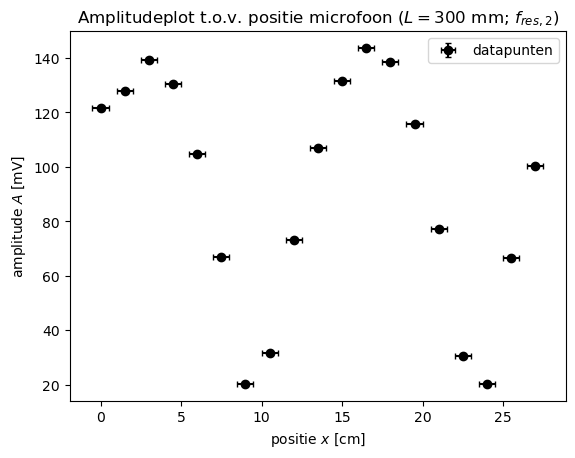

In [11]:
#proef 5 - wanneer stopt het (175 - 193)
alle_data_matrix = []
for i in data_getallen[174: 193]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A52 = []
alle_p52 = []
alle_chi52 = []
fout_A52 = []

for i in alle_data_matrix:
    t = 1e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i),1241, 1, 1], dV)
    alle_A52.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p52.append(res[1])
    alle_chi52.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A52.append(fout_A)
    #print(np.sqrt(np.diag(pcov)))
    print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 27.001, 1.5)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A52, fout_A52, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L = 300 \ \text{mm}$; $f_{res, 2}$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi23)


[5.98116473e+01 1.77731463e+03 5.87725952e-01 7.46326350e-01]
[6.43033559e+01 1.77740105e+03 5.88983837e-01 6.98022834e-01]
[4.51399823e+01 1.77740173e+03 5.84466523e-01 7.29967125e-01]
[2.57121377e+01 1.77739910e+03 5.55925985e-01 6.06568490e-01]
[-3.26802626e+00  1.77759950e+03  2.01674735e+00  7.31017403e-01]
[3.03258735e+01 1.77739375e+03 5.56691169e-01 8.70858064e-01]
[5.39675112e+01 1.77740246e+03 5.93801338e-01 6.73717772e-01]
[6.80854487e+01 1.77739466e+03 5.90719468e-01 7.76644750e-01]
[5.58620123e+01 1.77738934e+03 5.97644771e-01 6.65013871e-01]
[3.54340740e+01 1.77741470e+03 5.84910577e-01 6.50226614e-01]
[1.32258790e+01 1.77739596e+03 4.99608397e-01 7.13569073e-01]
[1.81171226e+01 1.77738583e+03 5.05710923e-01 8.21057880e-01]
[4.51255106e+01 1.77742422e+03 5.87324705e-01 7.21946243e-01]
[6.48850741e+01 1.77740906e+03 5.90986887e-01 6.78380152e-01]
[6.61423357e+01 1.77745841e+03 5.92267831e-01 6.51752697e-01]
[4.44273374e+01 1.77743406e+03 5.89267388e-01 7.68303343e-01]
[2.4

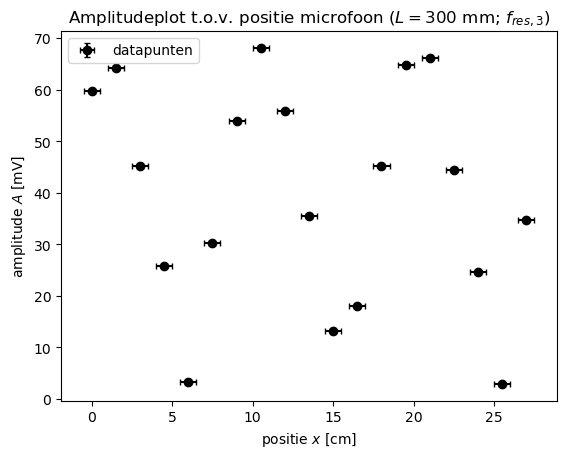

In [12]:
#proef 5 - wanneer stopt het (194 - 212)
alle_data_matrix = []
for i in data_getallen[193: 212]:
    alle_data_matrix.append(np.loadtxt(f'data_107_212/data_107_{i}.txt', skiprows = 9).T[1])


def sinus(x, A, f, phi, C):
    return A * np.sin(2 * np.pi * f * x + phi) + C

def chi_sq(fit, y, y_err, popt, x):
    chi_squared = np.sum(((y - fit) / y_err)**2)
    dof = len(x) - len(popt)
    p_value = chi2.sf(chi_squared, dof)
    return [chi_squared / dof, p_value]

alle_A53 = []
alle_p53 = []
alle_chi53 = []
fout_A53 = []

for i in alle_data_matrix:
    t = 1e-6 * (aan_box_matrix[0] - 1)
    dt = np.full(len(t), 1e-6, float)
    popt, pcov = opt.curve_fit(sinus, t, i, [np.max(i), 1778, 1, 1], dV)
    alle_A53.append(np.abs(popt[0]))
    res = chi_sq(popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], i, dV, popt, t)
    alle_p53.append(res[1])
    alle_chi53.append(res[0])
    fout_A = np.sqrt(np.diag(pcov))[0]
    fout_A53.append(fout_A)
    print(popt)
    #print(np.sqrt(np.diag(pcov)))
    #fig, ax = plt.subplots()
    #ax.scatter(t, i)
    #ax.plot(t, popt[0] * np.sin(2 * np.pi * popt[1] * t + popt[2]) + popt[3], color = 'red')
    continue

x = np.arange(0, 27.001, 1.5)
fig, ax = plt.subplots()
ax.errorbar(x, alle_A53, fout_A53, np.full(len(x), 0.5), fmt = 'o', color = 'black', capsize = 2.5, label = 'datapunten')
ax.set_title(r'Amplitudeplot t.o.v. positie microfoon ($L = 300 \ \text{mm}$; $f_{res, 3}$)')
ax.set_xlabel(r'positie $x$ [cm]')
ax.set_ylabel(r'amplitude $A$ [mV]')
ax.legend()
print(alle_chi23)

In [13]:
#proef 6 - staande golf verhouding
def r(Amax, Amin):
    return (Amax - Amin) / (Amax + Amin)

def fout_r(Amax, Amin, dAmax, dAmin):
    amax, amin = sp.symbols('amax amin')
    r = (amax - amin) / (amax+amin)
    s_func = sp.sqrt((sp.diff(r, amax))**2 * dAmax**2 + (sp.diff(r, amin))**2 * dAmin**2)
    s = s_func.subs([(amax, Amax), (amin, Amin)])
    return s

erren = []
dr = []
alle_A = [alle_A21, alle_A22, alle_A23, alle_A41, alle_A42, alle_A51, alle_A52, alle_A53]
alle_fout = [fout_A21, fout_A22, fout_A23, fout_A41, fout_A42, fout_A51, fout_A52, fout_A53]
ind_max = [0, 0, 0, 2, 0, 0, 11, 7]
ind_min = [21, 27, 29, 11, 6, 11, 16, 17] #hardcoden want waarom niet
for i in range(len(alle_A)):
    Amax = np.max(alle_A[i])
    Amin = np.min(alle_A[i])
    index_max = np.where(alle_A[i] == Amax)
    index_min = np.where(alle_A[i] == Amin)
    #print(index_max)
    #print(index_min)
    dAmax = alle_fout[i][ind_max[i]]
    dAmin = alle_fout[i][ind_max[i]]
    erren.append(r(Amax, Amin))
    dr.append(fout_r(Amax, Amin, dAmax, dAmin))

print(erren)
print(dr)

[0.9263479001342971, 0.9153981146772688, 0.8814517668766361, 0.8625529847762535, 0.9311712703801548, 0.9151839482038765, 0.7531412550376012, 0.9174080475666572]
[0.00117507900196469, 0.00114620439294044, 0.00103959811142000, 0.000780364913496048, 0.000586262922506258, 0.000494270221127732, 0.000979044224191897, 0.000549223394100606]


In [14]:
#geluidssnelheid

def v(f, n, L):
    return 2 * L * f / n

def dv(f, n, L, df, dL):
    F, l = sp.symbols('F l')
    v = 2 * l * F / n
    s_func = sp.sqrt((sp.diff(v, F))**2 * df**2 + (sp.diff(v, l))**2 * dL**2)
    s = s_func.subs([(F, f), (l, L)])
    return s

#proef 3
f3 = 2029.83419372 #Hz
df3 = 0.05664720999993733 #arbitrair
L3 = np.array([9.20, 17.7, 26.2, 34.8, 43.2, 51.8]) *1e-2 #cm → m
dL3 = np.full(len(L3), 0.5, float) *1e-2 #cm → m
n3 = [1, 2, 3, 4, 5, 6]
alle_v3 = []
dv3 = []
for i in range(len(L3)):
    alle_v3.append(v(f3, n3[i], L3[i]))
    dv3.append(dv(f3, n3[i], L3[i], df3, dL3[i]))

print(alle_v3)
print(np.array(dv3)/2)

#proef 5
#1
f51 = 668 #Hz
df51 = 200 #waarom niet
L51 = 30 *1e-2 #cm → m
dL51 = 0.5 *1e-2 #cm → m
n51 = 1
v51 = v(f51, n51, L51)
dv51 = dv(f51, n51, L51, df51, dL51)
print(v51, dv51/2)

#2
f52 = 1244 #Hz
df52 = 200 
L52 = 30 *1e-2 #cm → m
dL52 = 0.5 *1e-2 #cm → m
n52 = 2
v52 = v(f52, n52, L52)
dv52 = dv(f52, n52, L52, df52, dL52)
print(v52, dv52/2)

#3
f53 = 1777 #Hz
df53 = 200 
L53 = 30 *1e-2 #cm → m
dL53 = 0.5 *1e-2 #cm → m
n53 = 3
v53 = v(f53, n53, L53)
dv53 = dv(f53, n53, L53, df53, dL53)
print(v53, dv53/2)

[373.48949164448, 359.28065228843997, 354.54437250309337, 353.19114970728, 350.75534867481605, 350.48470411565336]
[10.1491723066493 5.07458796065507 3.38306060677547 2.53729752839111
 2.02984009428153 1.69153556451325]
400.8 60.0928914265240
373.2 30.1607708787425
355.40000000000003 20.2180975723347
